# Problem 1

In [2]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)


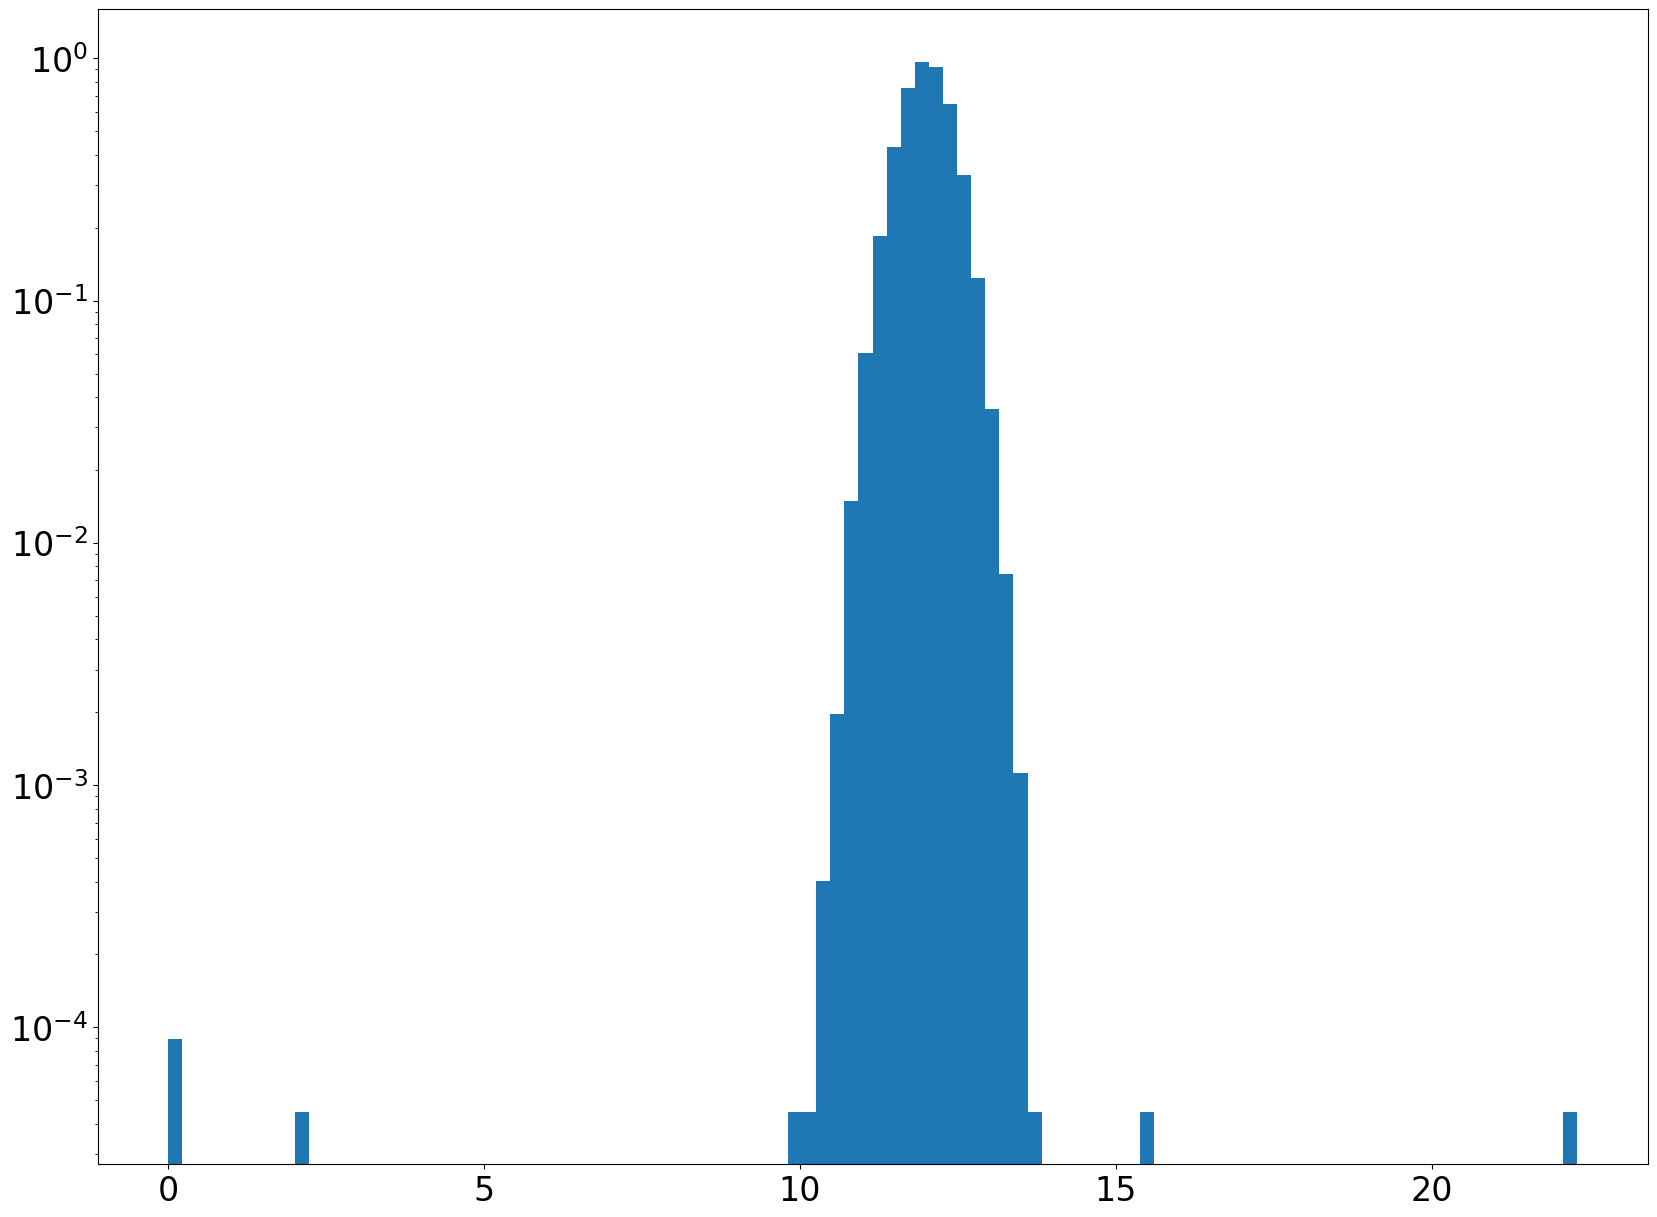

In [8]:
# adding in bad data points

d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

1A) The data is a Gaussian distribution with a center of 12, and a standard deviation of 0.4. To identify bad data, I will omit the data that falls outside the range of $ +/- 3\sigma $ 

1. Statistical Question:
2. In math:
3. 




1B) The smaller the threshold is, the more data will be thrown out. If there were a loose threshold where anything beyond $|Z| > 5$ or $6$ is discarded then very few data points would be omitted besides extreme outliers. If the threshold were to be decreased to $|Z| > 2.5$ or $3$ then we can say that about $1.2%$ or $0.3%$ of the data would be omitted respectively. Using the 68-95-99.7 rule, we know that at this level the amount of data that is omitted is predictable and a small amount of good data will be omitted at these thresholds.

1C) Yes, there are mistakes of commission. In the example given above, a data point at 12.7 is close to the mean. With $\sigma = 0.4$, the Z-value is $1.75$ for this point. This would be impossible to remove with thresholds, and it would be hard to discern that the data point itself is bad without having other context for what was happening when it was collected. With a dataset like this, we can say that bad data points remaining is not always avoidable but most outliers can be removed with a threshold that is large enough to not throw out a bunch of good data. (like $|Z| > 3$ or $|Z| > 6$) 


#### Truth Table

|                | True T |         Bad T  |
|----------------|-----------|-------------|
| ****    |         |           |
| ****  |          |            |



In [ ]:
#truth table

# Problem 2

<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_119/2517428479.py:9: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel("$\Delta $y arcseconds", fontsize = 18)
/tmp/ipykernel_119/2517428479.py:10: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel("$\Delta $x arcseconds", fontsize = 18)


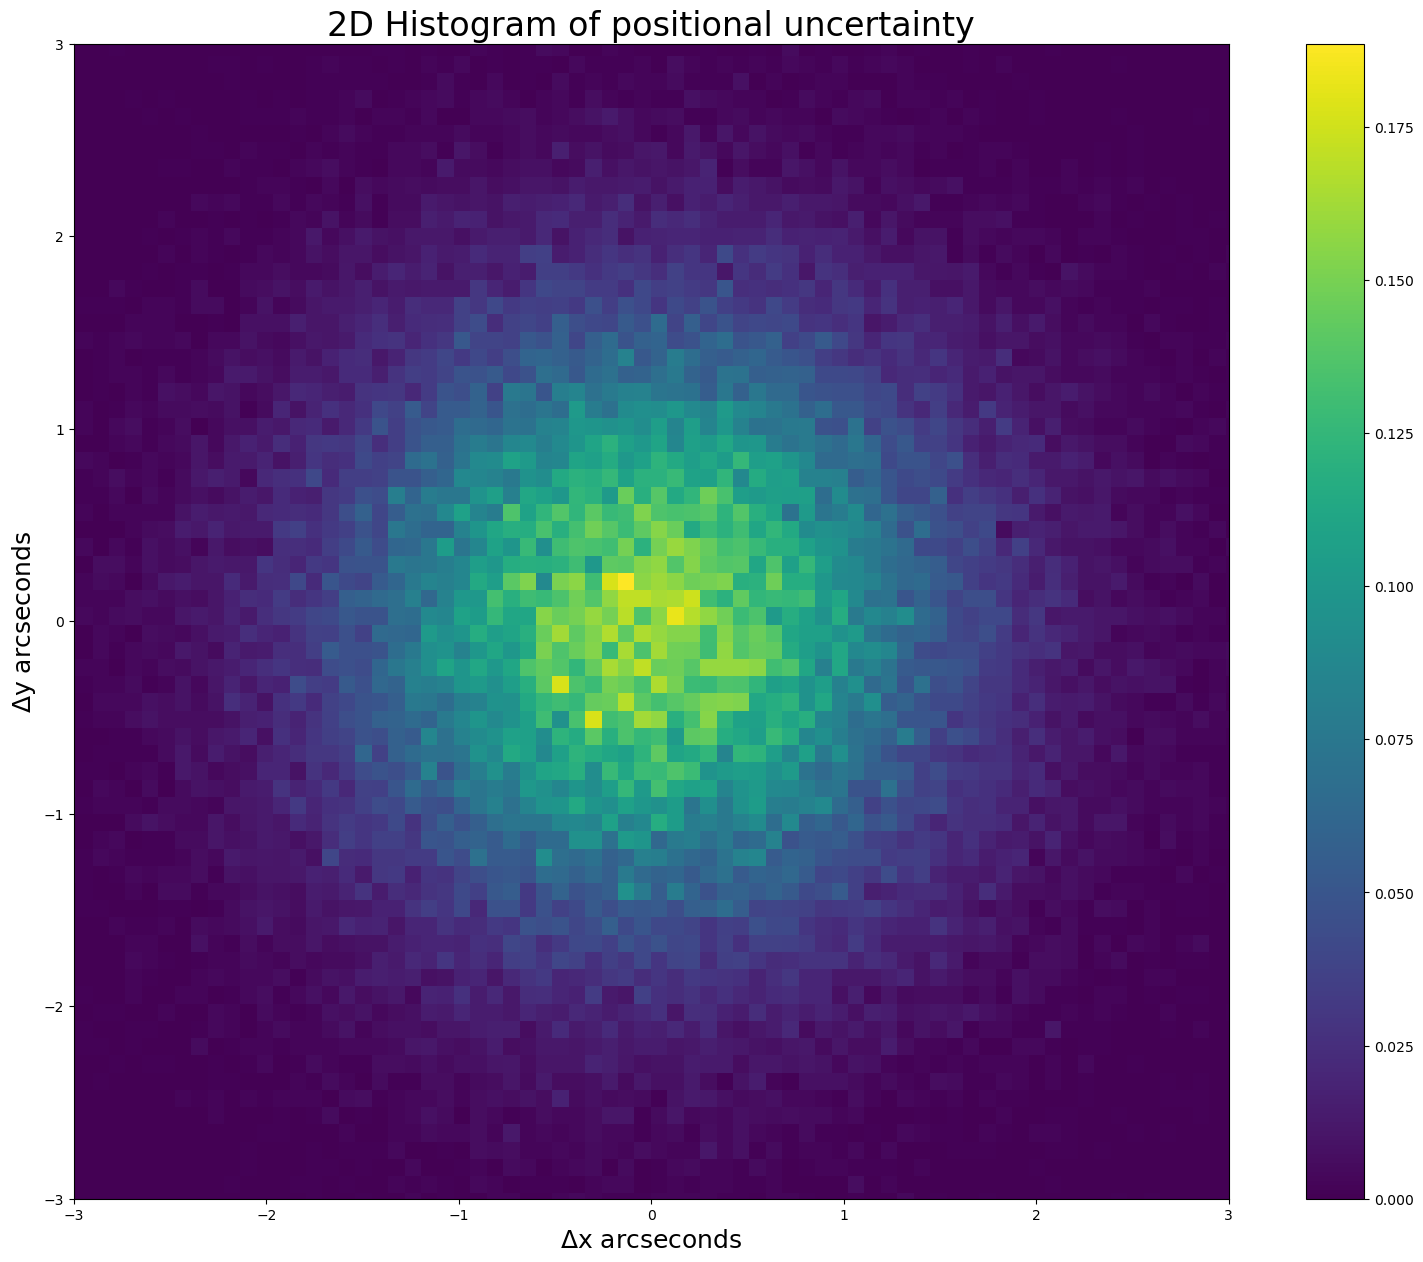

In [6]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
plt.xlabel("$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

The $\sigma$ value for the gaussian distribution is 1" in both X and Y. For a 5 sigma detection, the object would have to move 5" in the x or y direction, or $ \sqrt{\Delta x^2+\Delta y^2)} > 5 \sqrt{2}$

1. The question in words is: What change in distance is large enough to not have been produced by background noise from atmospheric and instrumental effects?

2. In math: The general formula for the pdf of a 2-D gaussian is the following:

$ f(x,y) = \frac{1}{2\pi\sigma_x\sigma_y\sqrt{1-\rho^2}} * \exp[-\frac{1}{2(1-\rho^2}(\frac{x-\mu_x}{\sigma_x^2}+\frac{y-\mu_y}{\sigma_y^2}+\frac{2\rho(x-\mu_x)(y-\mu_y)}{\sigma_x\sigma_y})$

With $\mu_x$ and $\mu_y$ being zero since the 2D gaussian distribution is centered at (0,0), and both $\sigma_x$ and $\sigma_y$ being 1, the mathematical representation of the probability density function simplifies to:

$ f(x,y) = \frac{1}{2\pi} e^{-\frac{x^2+y^2}{2}} $

3. a 5 sigma detection of motion corresponds to a change in distance of --- arcseconds


# Problem 3

If we observe for 8 hours per night for 15 days, and expect 1 cosmic ray per minute, then we predict 1 * 60 * 8 * 15 = **7200** cosmic rays over the period of 15 days of observation.

1. The question in words is: If there were no moon in the sky, how significant or likely is our actual detection of **6800** cosmic rays over the period of 15 days?

2. In math:
The distribution for this will be a poisson distribution, since there is a discrete number of events to be counted, and

$ P(X=k)=\frac{\lambda^k e^{-\lambda}}{k!}  $

$ P(X 


4. Converted to sigma:

$ Z = \frac{N-\mu}{\sigma} = \frac{6800-7200}{\sqrt{7200}} \approx -4.71 $

The sigma value is -4.71, close to the 5 sigma threshold for discovery

The unique aspect to this problem is that we are looking for the absence of signal instead of a really high signal like in other problems. This is because the moon should be absorbing some of the cosmic rays that we would have otherwise observed if it weren't there.

In [5]:
import math
from scipy.stats import norm, poisson

# 1. Define input parameters
rate_per_minute = 1
hours_per_night = 8
total_days = 15
observed_events = 6800

# 2. Calculate the total expected background (lambda)
total_minutes = hours_per_night * total_days * 60
expected_events = rate_per_minute * total_minutes  # 7200

# This calculates the exact sum of P(X = k) from k=0 to 6800
p_value_poisson = poisson.cdf(observed_events, expected_events)

mean = expected_events
std_dev = math.sqrt(expected_events)

# Z-score
z_score = (observed_events - mean) / std_dev
p_value_gauss = norm.cdf(z_score)


# 5. Print out the results
print(f"--- Cosmic Ray Moon Shadow Analysis ---")
print(f"Total Expected Background: {expected_events} counts")
print(f"Observed Background:            {observed_events} counts\n")

print(f"p-value:          {p_value_poisson:.5e}")
print(f"Significance:      {abs(z_score):.2f} sigma")


--- Cosmic Ray Moon Shadow Analysis ---
Total Expected Background: 7200 counts
Observed Background:            6800 counts

p-value:          1.01333e-06
Significance:      4.71 sigma
